In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [10]:
df = pd.read_csv("kc_house_data.csv")

In [11]:
df.head()

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,20141013T000000,221900.0,3,1.00,1180,5650,1.0,0,0,...,7,1180,0,1955,0,98178,47.5112,-122.257,1340,5650
1,6414100192,20141209T000000,538000.0,3,2.25,2570,7242,2.0,0,0,...,7,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639
2,5631500400,20150225T000000,180000.0,2,1.00,770,10000,1.0,0,0,...,6,770,0,1933,0,98028,47.7379,-122.233,2720,8062
3,2487200875,20141209T000000,604000.0,4,3.00,1960,5000,1.0,0,0,...,7,1050,910,1965,0,98136,47.5208,-122.393,1360,5000
4,1954400510,20150218T000000,510000.0,3,2.00,1680,8080,1.0,0,0,...,8,1680,0,1987,0,98074,47.6168,-122.045,1800,7503


In [12]:
df.drop_duplicates(inplace=True)

df['bedrooms'] = df['bedrooms'].replace(0, np.nan)
df['bathrooms'] = df['bathrooms'].replace(0, np.nan)

df['bedrooms'] = df['bedrooms'].fillna(df['bedrooms'].median())
df['bathrooms'] = df['bathrooms'].fillna(df['bathrooms'].median())

print(df.isnull().sum())

id               0
date             0
price            0
bedrooms         0
bathrooms        0
sqft_living      0
sqft_lot         0
floors           0
waterfront       0
view             0
condition        0
grade            0
sqft_above       0
sqft_basement    0
yr_built         0
yr_renovated     0
zipcode          0
lat              0
long             0
sqft_living15    0
sqft_lot15       0
dtype: int64


In [13]:
df['date'] = pd.to_datetime(df['date'])

df['sale_year'] = df['date'].dt.year

df['house_age'] = df['sale_year'] - df['yr_built']

df['renovation_age'] = np.where(
    df['yr_renovated'] > 0,
    df['sale_year'] - df['yr_renovated'],
    np.nan
)

df[['sale_year', 'house_age', 'renovation_age']].head()

,sale_year,house_age,renovation_age
0,2014,59,NaN
1,2014,63,23.0
2,2015,82,NaN
3,2014,49,NaN
4,2015,28,NaN


In [14]:
df['price_per_sqft_living'] = df['price'] / df['sqft_living']

df['price_per_sqft_lot'] = df['price'] / df['sqft_lot']

df[['price_per_sqft_living', 'price_per_sqft_lot']].head()

,price_per_sqft_living,price_per_sqft_lot
0,188.050847,39.274336
1,209.338521,74.288870
2,233.766234,18.000000
3,308.163265,120.800000
4,303.571429,63.118812


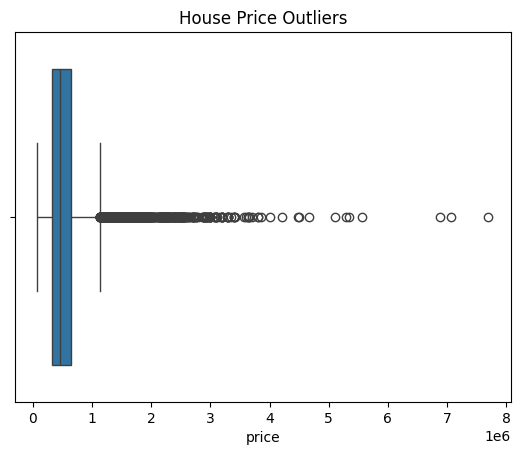

In [15]:
sns.boxplot(x=df['price'])
plt.title("House Price Outliers")
plt.show()

In [16]:
Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = df[(df['price'] < lower) | (df['price'] > upper)]

print("Number of outliers:", len(outliers))

Number of outliers: 1146


In [17]:
df.to_csv("cleaned_house_sales.csv", index=False)

print("Dataset saved successfully!")

Dataset saved successfully!
